# TP 2 — Classification de répliques avec le deep learning

**NLP et Transformers — CY Tech**  
**Jeu de données : Tiny Shakespeare (même problème que dans le TP1)**

---

L'idée de ce TP est de retrouver **qui parle à partir d'une réplique**. Pour voir ce qu'apporte vraiment un réseau neuronal, on le compare à deux références : une prédiction systématique de la classe majoritaire et un classifieur TF–IDF avec régression logistique.

On commence par préparer les données et établir les références classiques. Ensuite, on construit un **BiGRU** avec des embeddings appris sur le corpus, on suit sa validation et on analyse ses erreurs sur un test tenu à l'écart.


## 0. Préparer l’environnement

In [11]:
import os
import re
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 150)
print("Environnement prêt.")

import random
import copy
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__, "| device :", DEVICE)

Environnement prêt.
PyTorch : 2.11.0+cpu | device : cpu


## 1. Récupérer et examiner Tiny Shakespeare

On garde le même corpus que dans le TP1. Il est préférable de ne pas retirer automatiquement tous les mots fréquents : dans des dialogues de Shakespeare, des tournures comme « thou » ou « my lord » peuvent aider à distinguer les personnages.


In [12]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
# Option hors ligne : définir TINY_SHAKESPEARE_PATH vers une copie de input.txt.
fichier_corpus = os.environ.get("TINY_SHAKESPEARE_PATH", "")
if fichier_corpus:
    texte_source = Path(fichier_corpus).read_text(encoding="utf-8")
else:
    try:
        texte_source = urllib.request.urlopen(URL, timeout=30).read().decode("utf-8")
    except Exception as exc:
        raise RuntimeError(
            "Téléchargement impossible. Téléchargez input.txt depuis l'URL et définissez "
            "TINY_SHAKESPEARE_PATH vers ce fichier avant de relancer."
        ) from exc
print(f"Corpus : {len(texte_source):,} caractères ; {len(texte_source.splitlines()):,} lignes")
print(texte_source[:280])

Corpus : 1,115,394 caractères ; 40,000 lignes
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

F


## 2. Retrouver les répliques et définir les classes

In [13]:
def extraire_dialogues(txt: str) -> pd.DataFrame:
    """Reprend le découpage du corrigé TP1 : une réplique par bloc titré."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)

df = extraire_dialogues(texte_source)
df["n_mots"] = df["replique"].str.split().str.len()
NB_PERSONNAGES, TAILLE_MIN = 5, 5
personnages_retenus = df["locuteur"].value_counts().head(NB_PERSONNAGES).index.tolist()
corpus_filtre = (df[df["locuteur"].isin(personnages_retenus)]
           .query("n_mots >= @TAILLE_MIN")
           .loc[:, ["replique", "locuteur"]].reset_index(drop=True))
assert corpus_filtre["locuteur"].nunique() == NB_PERSONNAGES
print(f"{len(corpus_filtre)} répliques retenues ; classes : {personnages_retenus}")
print(corpus_filtre["locuteur"].value_counts())
corpus_filtre.head()

761 répliques retenues ; classes : ['GLOUCESTER', 'DUKE VINCENTIO', 'MENENIUS', 'ROMEO', 'PETRUCHIO']
locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64


,replique,locuteur
0,"What work's, my countrymen, in hand? where go you With bats and clubs? The matter? speak, I pray you.",MENENIUS
1,"Why, masters, my good friends, mine honest neighbours, Will you undo yourselves?",MENENIUS
2,"I tell you, friends, most charitable care Have the patricians of you. For your wants, Your suffering in this dearth, you may as well Strike at the...",MENENIUS
3,"Either you must Confess yourselves wondrous malicious, Or be accused of folly. I shall tell you A pretty tale: it may be you have heard it; But, s...",MENENIUS
4,"There was a time when all the body's members Rebell'd against the belly, thus accused it: That only like a gulf it did remain I' the midst o' the ...",MENENIUS


### Ce qu'on doit obtenir

- **Étiquette prédite :** le locuteur indiqué au début de chaque bloc de dialogue.
- **Cinq personnages :** certains locuteurs apparaissent trop peu pour être appris correctement ; on se limite donc aux cinq plus représentés.
- **Au moins cinq mots par réplique :** les répliques très courtes donnent peu de contexte pour identifier leur auteur.


## 3. Séparer les données avant d'apprendre quoi que ce soit

Le partage est de **60 % pour l'entraînement, 20 % pour la validation et 20 % pour le test**. La validation permet de contrôler l'apprentissage du réseau et de décider quand l'arrêter. Le test, lui, ne doit servir qu'à l'évaluation finale.

Pour garder une comparaison juste, les modèles classiques et le BiGRU utilisent exactement le même ensemble d'entraînement.


In [14]:
X_dev, X_test, y_dev, y_test = train_test_split(
    corpus_filtre["replique"], corpus_filtre["locuteur"],
    test_size=0.20, stratify=corpus_filtre["locuteur"], random_state=RANDOM_STATE,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE,
)
print(f"Train : {len(X_train)} | Validation : {len(X_val)} | Test : {len(X_test)}")
print(pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3))
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

Train : 456 | Validation : 152 | Test : 153
                train  validation   test
locuteur                                
GLOUCESTER      0.257       0.257  0.261
DUKE VINCENTIO  0.217       0.217  0.216
ROMEO           0.186       0.184  0.183
PETRUCHIO       0.173       0.178  0.176
MENENIUS        0.167       0.164  0.163


## 4. Commencer avec deux modèles simples

On mesure d'abord le score obtenu en choisissant toujours la classe majoritaire. Puis on entraîne une régression logistique sur les caractéristiques **TF–IDF** : mots isolés et paires de mots, `min_df=2`, `max_df=0.8`, sans retrait des stopwords. Cela servira de point de comparaison au réseau neuronal.


In [15]:
classifieur_majoritaire = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
pipeline_tfidf = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2),
                              min_df=2, max_df=0.8, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, C=5,
                               class_weight="balanced", random_state=RANDOM_STATE)),
])
classifieur_majoritaire.fit(X_train, y_train)
pipeline_tfidf.fit(X_train, y_train)
for nom, modele in [("Classe majoritaire", classifieur_majoritaire), ("TF–IDF + logistique", pipeline_tfidf)]:
    pred = modele.predict(X_val)
    print(f"{nom:<25} | validation accuracy={accuracy_score(y_val, pred):.3f} | "
          f"F1 macro={f1_score(y_val, pred, average='macro', zero_division=0):.3f}")

Classe majoritaire        | validation accuracy=0.257 | F1 macro=0.082
TF–IDF + logistique       | validation accuracy=0.599 | F1 macro=0.593


### Comment lire ces premiers scores ?

Prédire le personnage le plus fréquent donne une référence facile à battre en accuracy, mais cette méthode ignore complètement les autres personnages : son F1 macro sera donc limité.

TF–IDF, de son côté, exploite les mots et expressions caractéristiques des répliques. L'intérêt du réseau sera de voir s'il peut faire mieux, et pas simplement d'ajouter un modèle plus complexe.


## 5. Passer des textes aux séquences de tokens

Le réseau ne reçoit pas les vecteurs creux de TF–IDF. Chaque réplique est transformée en une **suite d'identifiants de mots**, puis le modèle apprend des représentations denses (embeddings).

Le vocabulaire est construit uniquement à partir de `X_train`. Les mots absents sont représentés par `<unk>`, le remplissage par `<pad>`, et chaque réplique est limitée à 80 tokens.


In [16]:
REGEX_MOTS = re.compile(r"[a-z]+(?:'[a-z]+)?")
LONGUEUR_MAX, SEUIL_FREQUENCE = 80, 2

def decouper_mots(phrase: str) -> list[str]:
    """Découpe une réplique en tokens anglais, sans supprimer les stopwords."""
    return REGEX_MOTS.findall(phrase.lower())

comptage_mots = Counter(mot for phrase in X_train for mot in decouper_mots(phrase))
vocabulaire = {"<pad>": 0, "<unk>": 1}
for mot, n in sorted(comptage_mots.items()):
    if n >= SEUIL_FREQUENCE:
        vocabulaire[mot] = len(vocabulaire)

classes = sorted(y_train.unique())
id_par_classe = {label: i for i, label in enumerate(classes)}

def encoder_texte(phrase: str) -> list[int]:
    """Convertit les tokens en IDs, avec repli sur <unk> et longueur limitée."""
    ids = [vocabulaire.get(mot, vocabulaire["<unk>"]) for mot in decouper_mots(phrase)[:LONGUEUR_MAX]]
    return ids if ids else [vocabulaire["<unk>"]]

assert vocabulaire["<pad>"] == 0 and vocabulaire["<unk>"] == 1
assert all(0 <= i < len(vocabulaire) for i in encoder_texte("unknownword"))
print(f"Vocabulaire appris sur le train : {len(vocabulaire)} tokens")
print("Exemple :", decouper_mots(X_train.iloc[0])[:15])
print("IDs     :", encoder_texte(X_train.iloc[0])[:15])

Vocabulaire appris sur le train : 1285 tokens
Exemple : ['they', 'will', 'then', "ere't", 'be', 'long']
IDs     : [1095, 1229, 1088, 1, 74, 655]


### Ce qu'il faut garder en tête

Avec ses unigrammes et bigrammes, TF–IDF conserve peu d'informations sur l'ordre des mots. Le BiGRU peut suivre la séquence dans les deux directions, ce qui lui donne davantage de contexte.

En revanche, ses embeddings doivent être appris à partir d'un corpus plutôt réduit : ce n'est pas comparable à un Transformer préentraîné sur des volumes de texte beaucoup plus importants.


## 6. Regrouper les répliques en mini-lots

In [17]:
class JeuDeRepliques(Dataset):
    """Stocke les répliques encodées et leurs classes numériques."""
    def __init__(self, textes, etiquettes):
        self.textes = [encoder_texte(x) for x in textes]
        self.labels = [id_par_classe[y] for y in etiquettes]

    def __len__(self):
        return len(self.textes)

    def __getitem__(self, index):
        return torch.tensor(self.textes[index], dtype=torch.long), self.labels[index]


def preparer_lot(batch):
    """Assemble des séquences inégales avec padding et longueurs réelles."""
    sequences, labels = zip(*batch)
    longueurs = torch.tensor([len(s) for s in sequences], dtype=torch.long)
    x = pad_sequence(sequences, batch_first=True, padding_value=0)
    y = torch.tensor(labels, dtype=torch.long)
    return x, longueurs, y

BATCH_SIZE = 32
chargeur_train = DataLoader(JeuDeRepliques(X_train, y_train), batch_size=BATCH_SIZE,
                      shuffle=True, collate_fn=preparer_lot,
                      generator=torch.Generator().manual_seed(RANDOM_STATE))
chargeur_validation = DataLoader(JeuDeRepliques(X_val, y_val), batch_size=BATCH_SIZE,
                    shuffle=False, collate_fn=preparer_lot)
chargeur_test = DataLoader(JeuDeRepliques(X_test, y_test), batch_size=BATCH_SIZE,
                     shuffle=False, collate_fn=preparer_lot)

x_ex, longueurs_ex, y_ex = next(iter(chargeur_train))
assert x_ex.shape[0] == len(y_ex) == len(longueurs_ex)
print("Tensor d'entrée :", tuple(x_ex.shape))
print("Longueurs réelles (extrait) :", longueurs_ex[:6].tolist())

Tensor d'entrée : (32, 80)
Longueurs réelles (extrait) : [26, 17, 17, 10, 8, 57]


## 7. Définir le réseau : embeddings, BiGRU, puis sortie

Le modèle utilise des embeddings de **64 dimensions**, une GRU bidirectionnelle de **48 unités dans chaque sens**, du dropout, puis une couche linéaire qui produit un score pour chacun des cinq personnages.

Les états issus des deux directions sont réunis pour résumer la réplique avant la classification.


In [18]:
class ModeleBiGRU(nn.Module):
    """Classe une réplique en tenant compte de son ordre de tokens."""
    def __init__(self, n_vocab: int, n_classes: int, emb_dim: int = 64, hidden: int = 48):
        super().__init__()
        self.embedding = nn.Embedding(n_vocab, emb_dim, padding_idx=0)
        self.gru = nn.GRU(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.35)
        self.sortie = nn.Linear(hidden * 2, n_classes)

    def forward(self, x, longueurs):
        emb = self.embedding(x)
        packed = pack_padded_sequence(emb, longueurs.cpu(),
                                     batch_first=True, enforce_sorted=False)
        _, h = self.gru(packed)
        representation = torch.cat([h[-2], h[-1]], dim=1)
        return self.sortie(self.dropout(representation))

modele_gru = ModeleBiGRU(len(vocabulaire), len(classes)).to(DEVICE)
print(modele_gru)
print("Paramètres entraînables :", sum(p.numel() for p in modele_gru.parameters() if p.requires_grad))
assert modele_gru(x_ex.to(DEVICE), longueurs_ex).shape == (len(y_ex), len(classes))

ModeleBiGRU(
  (embedding): Embedding(1285, 64, padding_idx=0)
  (gru): GRU(64, 48, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.35, inplace=False)
  (sortie): Linear(in_features=96, out_features=5, bias=True)
)
Paramètres entraînables : 115557


## 8. Entraîner le BiGRU sans toucher au test

Pour l'optimisation, on utilise **AdamW** et une fonction de perte **cross-entropy pondérée**. On limite aussi la norme du gradient afin de stabiliser l'entraînement.

À chaque époque, on vérifie le **F1 macro de validation**. Si celui-ci cesse de progresser, l'early stopping interrompt l'entraînement et l'on récupère les meilleurs poids enregistrés. Le jeu de test reste inutilisé pendant cette étape.


In [19]:
nb_par_classe = y_train.value_counts().reindex(classes).values.astype(float)
ponderation_classes = torch.tensor(len(y_train) / (len(classes) * nb_par_classe),
                     dtype=torch.float32, device=DEVICE)
critere_perte = nn.CrossEntropyLoss(weight=ponderation_classes)
optimizer_gru = torch.optim.AdamW(modele_gru.parameters(), lr=1e-3, weight_decay=1e-3)


def evaluer_modele(loader):
    """Retourne loss, labels et prédictions sans mise à jour des poids."""
    modele_gru.eval()
    total, n = 0.0, 0
    vrais, predicts = [], []
    with torch.no_grad():
        for x, longueurs, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = modele_gru(x, longueurs)
            total += critere_perte(logits, y).item() * len(y)
            n += len(y)
            vrais.extend(y.cpu().tolist())
            predicts.extend(logits.argmax(dim=1).cpu().tolist())
    return total / n, np.array(vrais), np.array(predicts)

EPOCHS = int(os.environ.get("TP2_EPOCHS", "12"))
PATIENCE = 3
suivi_entrainement = []
f1_optimal, perte_optimale, poids_optimaux = -1.0, float("inf"), None
compteur_patience = 0

for epoch in range(1, EPOCHS + 1):
    modele_gru.train()
    cumul, n = 0.0, 0
    for x, longueurs, y in chargeur_train:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer_gru.zero_grad(set_to_none=True)
        logits = modele_gru(x, longueurs)
        perte = critere_perte(logits, y)
        perte.backward()
        nn.utils.clip_grad_norm_(modele_gru.parameters(), max_norm=1.0)
        optimizer_gru.step()
        cumul += perte.item() * len(y)
        n += len(y)

    val_loss, yv, pv = evaluer_modele(chargeur_validation)
    val_f1 = f1_score(yv, pv, average="macro", zero_division=0)
    train_loss = cumul / n
    suivi_entrainement.append({"epoch": epoch, "train_loss": train_loss,
                       "val_loss": val_loss, "val_f1_macro": val_f1})
    print(f"Époque {epoch:02d} | train loss={train_loss:.3f} "
          f"| val loss={val_loss:.3f} | val F1 macro={val_f1:.3f}")

    if val_f1 > f1_optimal + 1e-5 or (abs(val_f1 - f1_optimal) <= 1e-5 and val_loss < perte_optimale):
        f1_optimal, perte_optimale = val_f1, val_loss
        poids_optimaux = copy.deepcopy(modele_gru.state_dict())
        compteur_patience = 0
    else:
        compteur_patience += 1
        if compteur_patience >= PATIENCE:
            print("Arrêt anticipé : pas d'amélioration sur validation.")
            break

assert poids_optimaux is not None
modele_gru.load_state_dict(poids_optimaux)
print(f"Meilleur F1 macro validation : {f1_optimal:.3f}")

Époque 01 | train loss=1.643 | val loss=1.628 | val F1 macro=0.187
Époque 02 | train loss=1.577 | val loss=1.619 | val F1 macro=0.211
Époque 03 | train loss=1.531 | val loss=1.614 | val F1 macro=0.264
Époque 04 | train loss=1.490 | val loss=1.612 | val F1 macro=0.262
Époque 05 | train loss=1.437 | val loss=1.611 | val F1 macro=0.266
Époque 06 | train loss=1.389 | val loss=1.608 | val F1 macro=0.244
Époque 07 | train loss=1.323 | val loss=1.608 | val F1 macro=0.236
Époque 08 | train loss=1.241 | val loss=1.609 | val F1 macro=0.264
Arrêt anticipé : pas d'amélioration sur validation.
Meilleur F1 macro validation : 0.266


### 8.1 Observer les pertes au fil des époques

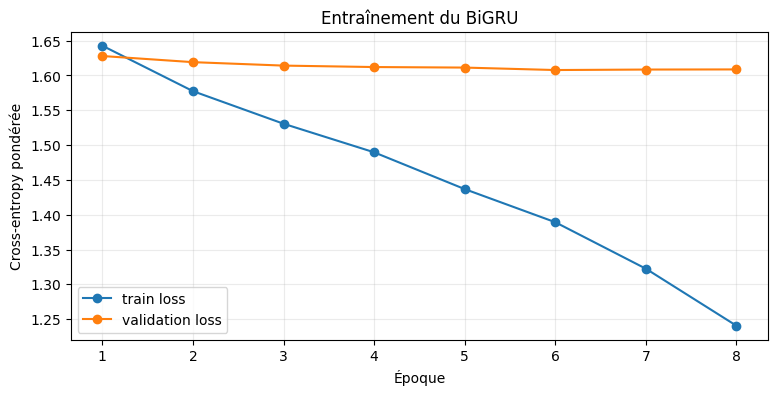

 epoch  train_loss  val_loss  val_f1_macro
     1       1.643     1.628         0.187
     2       1.577     1.619         0.211
     3       1.531     1.614         0.264
     4       1.490     1.612         0.262
     5       1.437     1.611         0.266
     6       1.389     1.608         0.244
     7       1.323     1.608         0.236
     8       1.241     1.609         0.264


In [20]:
suivi_df = pd.DataFrame(suivi_entrainement)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(suivi_df["epoch"], suivi_df["train_loss"], "o-", label="train loss")
ax.plot(suivi_df["epoch"], suivi_df["val_loss"], "o-", label="validation loss")
ax.set_xlabel("Époque")
ax.set_ylabel("Cross-entropy pondérée")
ax.set_title("Entraînement du BiGRU")
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print(suivi_df.round(3).to_string(index=False))

### Interpréter l'évolution des courbes

- Si la perte d'entraînement diminue alors que celle de validation augmente, le modèle commence peut-être à **surapprendre**.
- Si les performances restent faibles sur les deux jeux, le signal est possiblement trop difficile à apprendre ou le modèle manque d'entraînement.
- Si le **F1 macro sur validation** stagne, poursuivre sans changer la démarche apporte généralement peu.

Ces courbes donnent des indices ; elles ne suffisent pas, à elles seules, à expliquer les prédictions.


## 9. Comparer les trois approches sur le même test

In [21]:
_, vrais_ids, preds_ids = evaluer_modele(chargeur_test)
predictions_gru = np.array([classes[i] for i in preds_ids])
assert (np.array([classes[i] for i in vrais_ids]) == y_test.to_numpy()).all()

predictions = {
    "Classe majoritaire": classifieur_majoritaire.predict(X_test),
    "TF–IDF + régression logistique": pipeline_tfidf.predict(X_test),
    "BiGRU (depuis zéro)": predictions_gru,
}
lignes = []
for nom, pred in predictions.items():
    lignes.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_test, pred),
        "précision macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "rappel macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1 pondéré": f1_score(y_test, pred, average="weighted", zero_division=0),
    })
tableau_scores = pd.DataFrame(lignes).set_index("modèle")
print(tableau_scores.round(3).to_string())
print("\nRapport détaillé du BiGRU :")
print(classification_report(y_test, predictions_gru, labels=classes, zero_division=0))

                                accuracy  précision macro  rappel macro  F1 macro  F1 pondéré
modèle                                                                                       
Classe majoritaire                 0.261            0.052         0.200     0.083       0.108
TF–IDF + régression logistique     0.647            0.649         0.641     0.643       0.647
BiGRU (depuis zéro)                0.248            0.239         0.250     0.238       0.238

Rapport détaillé du BiGRU :
                precision    recall  f1-score   support

DUKE VINCENTIO       0.27      0.36      0.31        33
    GLOUCESTER       0.22      0.17      0.19        40
      MENENIUS       0.20      0.16      0.18        25
     PETRUCHIO       0.28      0.41      0.33        27
         ROMEO       0.22      0.14      0.17        28

      accuracy                           0.25       153
     macro avg       0.24      0.25      0.24       153
  weighted avg       0.24      0.25      0.24      

Le **F1 macro** est particulièrement utile ici, car il accorde la même importance aux cinq personnages. Une accuracy correcte pourrait sinon cacher un modèle performant seulement sur les locuteurs les plus fréquents.

Les scores sont calculés avec **60 % du corpus pour l'entraînement**, contrairement au TP1 corrigé, qui utilisait un découpage différent. Il ne faut donc pas comparer directement les chiffres sans tenir compte de ce point.


### 9.1 Examiner les matrices de confusion

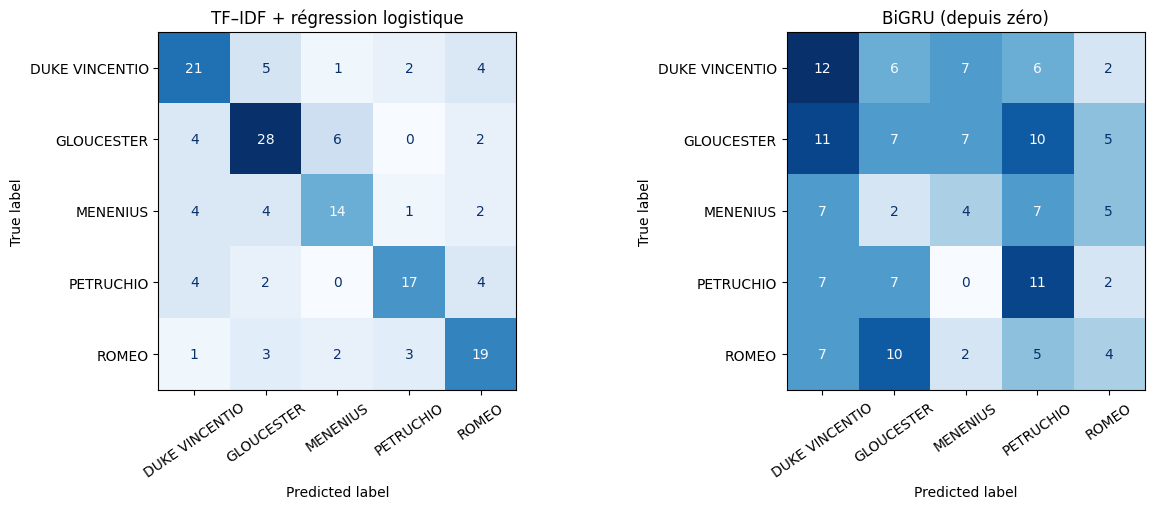

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (nom, pred) in zip(axes, list(predictions.items())[1:]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=classes, ax=ax, colorbar=False,
        xticks_rotation=35, cmap="Blues", values_format="d")
    ax.set_title(nom)
plt.tight_layout()
plt.show()

### 9.2 Regarder cinq répliques mal classées

In [23]:
exemples_errones = pd.DataFrame({
    "replique": X_test.to_numpy(),
    "vrai": y_test.to_numpy(),
    "prédit_DL": predictions_gru,
    "prédit_ML": predictions["TF–IDF + régression logistique"],
})
exemples_errones = exemples_errones[exemples_errones["vrai"] != exemples_errones["prédit_DL"]]
print(f"BiGRU : {len(exemples_errones)} erreurs sur {len(X_test)} répliques du test.\n")
for _, ligne in exemples_errones.head(5).iterrows():
    print(f"VRAI : {ligne['vrai']} | BiGRU : {ligne['prédit_DL']} | ML : {ligne['prédit_ML']}")
    print("Réplique :", ligne["replique"][:260], "\n")

BiGRU : 115 erreurs sur 153 répliques du test.

VRAI : ROMEO | BiGRU : GLOUCESTER | ML : GLOUCESTER
Réplique : Switch and spurs, switch and spurs; or I'll cry a match. 

VRAI : MENENIUS | BiGRU : DUKE VINCENTIO | ML : MENENIUS
Réplique : Cannot be! We have record that very well it can, And three examples of the like have been Within my age. But reason with the fellow, Before you punish him, where he heard this, Lest you shall chance to whip your information And beat the messenger who bids bewa 

VRAI : GLOUCESTER | BiGRU : DUKE VINCENTIO | ML : GLOUCESTER
Réplique : By so much is the wonder in extremes. 

VRAI : DUKE VINCENTIO | BiGRU : GLOUCESTER | ML : DUKE VINCENTIO
Réplique : Slandering a prince deserves it. She, Claudio, that you wrong'd, look you restore. Joy to you, Mariana! Love her, Angelo: I have confess'd her and I know her virtue. Thanks, good friend Escalus, for thy much goodness: There's more behind that is more gratulate 

VRAI : ROMEO | BiGRU : PETRUCHIO | ML : ROMEO
Ré

### Discussion des résultats

**Quel modèle fonctionne le mieux ?** C'est la colonne du **F1 macro** qui permet de trancher une fois le notebook exécuté. Sur un petit ensemble de données, un BiGRU entraîné de zéro peut très bien rester derrière TF–IDF.

**Qu'apporte le BiGRU ?** Contrairement à une simple représentation de fréquence, il peut exploiter la progression et l'ordre des mots dans une réplique.

**Pourquoi peut-il se tromper ?** Les répliques sont parfois courtes, ambiguës ou formulées avec un vocabulaire partagé par plusieurs personnages. Le faible nombre d'exemples rend aussi l'apprentissage de représentations robustes difficile.

**Comment interpréter une amélioration ?** Il faut la rapporter aux scores effectivement calculés, aux différences entre les classes et à la taille de l'échantillon, sans supposer qu'un modèle plus complexe gagne systématiquement.


## 10. Pour aller un peu plus loin : la longueur des répliques

Une réplique longue laisse davantage d'indices sur son locuteur. On peut donc regrouper les prédictions selon la longueur du texte et regarder si le BiGRU échoue plus souvent sur les extraits courts. Cette analyse se fait **sans réentraîner** le réseau.


In [24]:
analyse_par_taille = pd.DataFrame({
    "n_mots": [len(t.split()) for t in X_test],
    "correct": (predictions_gru == y_test.to_numpy()).astype(int),
})
analyse_par_taille["tranche"] = pd.cut(analyse_par_taille["n_mots"],
                                     bins=[0, 10, 25, 60, np.inf],
                                     labels=["5–10", "11–25", "26–60", ">60"])
print(analyse_par_taille.groupby("tranche", observed=False).agg(
    n=("correct", "size"), accuracy=("correct", "mean")).round(3))

          n  accuracy
tranche              
5–10     51     0.294
11–25    50     0.200
26–60    28     0.286
>60      24     0.208


---

## Bilan du TP

On a repris le problème d'identification du locuteur sur **Tiny Shakespeare**, avec les cinq personnages les plus fréquents et des répliques d'au moins cinq mots. Les jeux d'entraînement, de validation et de test restent distincts tout au long du TP.

La méthode **TF–IDF + régression logistique** donne une première référence solide. Le **BiGRU** utilise, lui, des embeddings appris et prend en compte l'ordre des mots, mais il doit apprendre ces représentations à partir d'un petit corpus.

L'intérêt de la comparaison ne se limite pas à l'accuracy : le **F1 macro**, les matrices de confusion et l'examen des erreurs montrent plus précisément les qualités et les limites de chaque approche. On ne conclut sur le meilleur modèle qu'à partir des résultats de l'exécution.
